# chip_11f_jjplacer — JX_500 trilayer junctions placed on probe-pad pairs, on the Quantcore PDK

## 1 · What the chip is

**Source:** `components/python/chip_11f_JJplacer.py` (module-level script, writes `chip_11m_placed.gds`, cell `JJx`),
Quantcore internal. Spec: `docs/designs/legacy/chip_11f_jjplacer.md`. For every row `x, y, f` of `jj_coordinates.csv`
it inserts chip_11m's `JX_500` junction cell (`chip_11m_TestJJ16x_pads.create_testPad(1.0, 0.6)`: straight finger 0.2
µm, bent finger 0.6 µm, HSQ) at `Trans(f, False, x, y)`. It draws nothing else: the junctions were placed onto a pad
chip from another mask.

**The coordinates file is lost** (the design decision): "ideally the junctions land in the centre of the top and bottom
pads, the part that is deleted, with 1 µm overlap". The pad chip is chip_11m's probe-pad pair — commented out of
`chip_11m_TestJJ16x_pads.py`: a 600 × 1000 µm etched window holding a 500 µm top pad and a 500 µm bottom pad, with the
junction in the centre cut-out between them. Rebuilt as **16 pad pairs** ("TestJJ16x"), 4 × 4 at a 1000 × 1500 µm
pitch around the die centre, each a `ProbePadPair` (upper pad on 1/0, lower pad in the 3/0 second metal,
`middle_height = 10` µm so the pad edges end ±5 µm from the centre), with **one `JX_500` per pair at the centre of
the gap** (its 12 µm window reaches 6 µm each way: it overlaps each pad by 1 µm).

| | the rebuild keeps (source-faithful) | the Quantcore PDK changes |
|---|---|---|
| pad pairs, junctions | 16 `ProbePadPair`s with the `Trilayer Junction Compact` (`JX_500`, 0.2 × 0.6 µm) at the centre of each gap, 1 µm window overlap onto each pad (#23); site count, pitch and pad lead are assumed (the CSV and the pad mask are lost) | the junctions valued on the PDK process: 112.5 kΩ (L_J 16.8 nH) → **flagged** (`pdk_rn` × 16), not retuned |
| bond pads | — (probe pads belong to the test structures; no bond pads or launchers) | the pad rule (`frame.pad_edge`, 100 µm) has nothing to move (step 4) |
| cheese | — (the source has none) | the **PDK band** (3 rows of 5 µm squares, 20 µm gaps, around the 3/0 keep-outs; `cheese: "auto"`), drawn by the build and kept by the fab mask |
| placement | — (the CSV is lost) | the 4 × 4 sites around the die centre: centred (step 7) |
| frame | — | the PDK die frame and device ID `CHIP11F` |
| FEM | — | no sim groups: nothing to excite (steps 11–12 say so) |

**Reproduced exactly** (step 15): the `JX_500` junction cell on every junction layer (one site compared). The pads have no legacy drawing (the pad mask is lost; their geometry follows chip_11m's commented-out code).

### Changes after design review (2026-11-03)

- **Rebuilt (2026-11-03):** a new notebook (the coordinates file is lost); junction
  values on the PDK junction rule (Nb, Δ = 1.4 meV, PDK process R_n·A 13.5 kΩ·µm²): 0.2 × 0.6 µm → R_n = 112.5 kΩ
  (L_J 16.8 nH).

### PDK conformance pass (notebooks-legacy, 2026-11-18)

- **Pads:** none. The probe pads belong to the test structures and are not bond pads or launchers, so the pad rule
  (`frame.pad_edge`, 100 µm) has nothing to move; `C.pads_md(d)` confirms it (step 7).
- **Centring:** `L.center_circuit` (each axis only if > 50 µm off): shift (0, 0): the 4 × 4 sites are placed around the die centre.
- **Cheese:** the source has none, so the PDK band applies (`cheese: "auto"`), drawn by the build and kept by the
  fab mask.
- **Junctions:** the legacy fingers, valued on the PDK process; `pdk_rn` flags a junction outside 40–50 kΩ (only
  cells that carry lumped junction values are checked), never retuned.
- **No FEM groups** (nothing to excite): steps 11 and 12 say so.
- Educative layout: one step per stage; the steps that do not apply to a test chip (pads, routes, FEM) say so.

## 2 · Setup and the Quantcore PDK

The helpers keep the cells short: `_common` (`C`) holds the netlist / LOM / FEM-export / snapshot helpers and
the PDK checks shared by every design notebook; `_legacy` (`L`) maps the legacy PCell parameters onto the
Quantcore cells, draws the legacy reference with the author's own legacy code (read-only), and holds the step
helpers of these notebooks (`_legacy_b`, `LB`, adds the legacy cells of the later chips). `LIVE` decides whether the design is pushed to a running KLayout (`QCC_LIVE=0`
for batch runs: nothing reaches KLayout).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                       # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "legacy"))
LIVE = os.environ.get("QCC_LIVE", "1") == "1"       # live KLayout by default; QCC_LIVE=0 for batch runs
import _common as C                                  # netlist / LOM / FEM-export / snapshot / PDK-check helpers
import _legacy as L                                  # legacy frame shift, parameter mapping, legacy reference, steps
import _legacy_b as LB                               # Connector Pad 2, holes, labels, xjc scripts, junction XOR

from IPython.display import Image, Markdown, display
from quantcore_circuits.designer import Designer
from quantcore_circuits.pdk import get_pdk

ID, OUT = "chip_11f_jjplacer", Path("examples/designs/legacy")

The PDK facts this rebuild uses, read from `get_pdk()` (nothing below is typed in by hand). The rules that
change a legacy chip are the **pad rule** (step 4), the **junction rule** (step 5), the **3/0 keep-out**
and the **cheese rule** (drawn by the build, step 14) and the centring of the content (step 7).

In [3]:
CHEESE_NOTE = 'PDK band (auto) — the source has no cheese of its own'
display(Markdown(L.pdk_facts_md(CHEESE_NOTE)))

| PDK item | value |
|---|---|
| PDK | `quantcore_nb_sapphire_v1` (version 3) |
| stack | sapphire, 650 µm, ε_r 10.25; Nb film (sheet metal in the FEM exports, 0.2 µm for the analytic CPW formulas) |
| CPW default | 10 µm centre, 6 µm gap, bends r = 100 µm |
| die frame | L-shaped dicing markers 25 µm wide (250 µm legs, 1000/0), 3 × 3 alignment grids (1001/0) in 500 µm corner squares, design area 100 µm inside the die edge, device ID optional (bottom centre, or beside the pads) |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (the design-area margin) from the die edge, whatever the original did (`edge="auto"`, DRC design warning `pad_edge`) |
| junction rule | Nb/AlOx/Nb trilayer, Δ = 1.4 meV (I_c·R_n = πΔ/2e), R_n 40–50 kΩ (nominal 45), qubits 4–8 GHz; R_n·A 13500 Ω·µm² and C_J 50 fF/µm² assumed; cells `Quantcore Junction` / `Quantcore Squid` (DRC design warnings `pdk_rn`, `pdk_fq`: flagged, never retuned) |
| 3/0 keep-out | second-metal etch: routes + 10 µm, components' etch bbox + 24 µm, other 1/0 shapes + 9 µm (filled) |
| cheese rule | 3 rows of 5 µm squares, 20 µm gaps, in a band around the 3/0 keep-outs; **the original design's own cheese wins** (chip `cheese`: `"auto"` / `"pdk"` / `"original"`). This chip: PDK band (auto) — the source has no cheese of its own |

### The source's numbers

chip_11f_JJplacer.py's junction (`JX_500` = chip_11m `create_testPad(1.0, 0.6)`) and chip_11m's commented-out pad
pair (µm, legacy frame: die centre at (0, 0)); the gap follows from the 1 µm overlap rule (#23).

In [4]:
# chip_11f_JJplacer.py + chip_11m's commented-out pad pair (legacy frame, µm)
SIZE, SECOND = 1.0, 0.6                       # JX_500 = chip_11m create_testPad(1.0, 0.6)
FINGER = 0.2 * SIZE                           # straight finger 0.2 µm (no bias)
WINDOW = 12.0                                 # JX window (junction_width + 1)
OVERLAP = 1.0                                 # junction window overlaps each pad by 1 µm
GAP = WINDOW - 2 * OVERLAP                    # pad-to-pad distance = middle_height = cut-out = 10 µm (pads at ±5)
PADS = dict(pad_width=500, upper_pad_height=495, lower_pad_height=495,    # 600 × 1000 µm window (the legacy size)
            middle_height=GAP, cutout=GAP)
SITES = [(x, y) for y in (2250, 750, -750, -2250) for x in (-1500, -500, 500, 1500)]   # 16 pairs ("16x")

## 3 · The die and the frame

`Designer(ID, box=...)` starts an empty 7.5 × 7.5 mm die (the PDK standard die). The PDK frame is drawn on every
build: four L-shaped dicing markers (1000/0), the 3 × 3 alignment grids (1001/0), the chip boundary (100/0) and the
device ID `CHIP11F` (`name_chip`; optional: the frame places it where it is free). The chip parameter
`cheese` is left at `"auto"`: the source has no cheese, so the build draws the PDK band (visible from step 5 on).

(0.0, 0.0, 7500.0, 7500.0) quantcore_nb_sapphire_v1


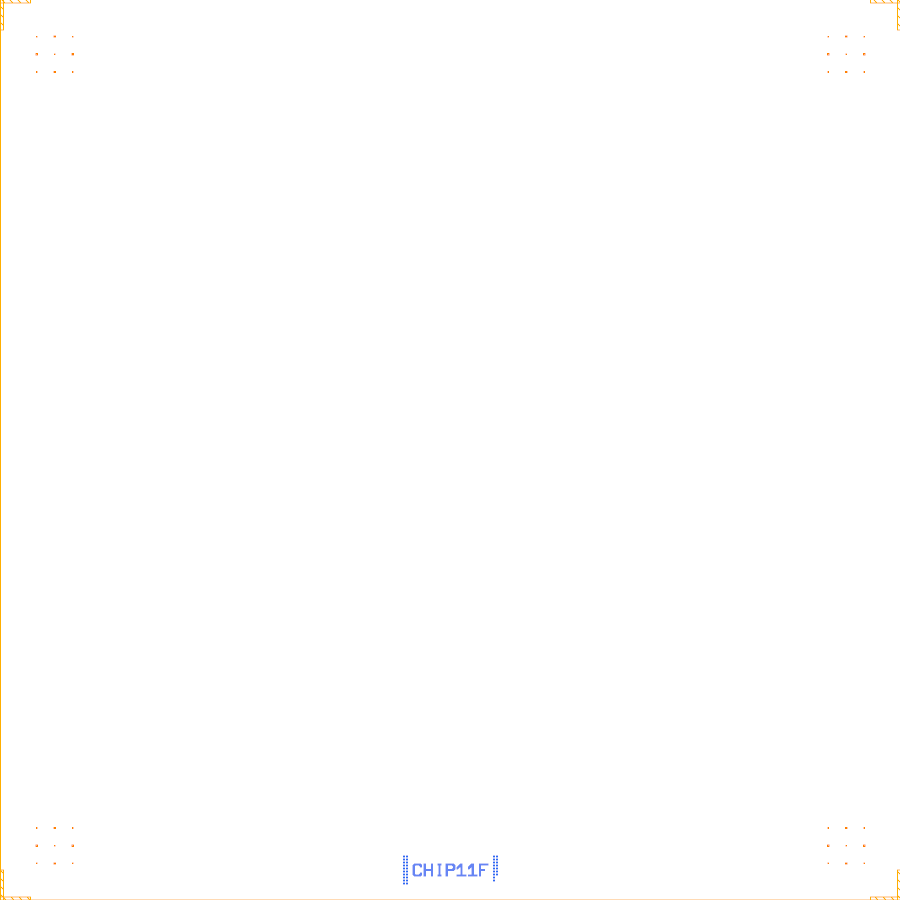

WindowsPath('build/legacy_steps/chip_11f_jjplacer_1_frame.png')

In [5]:
d = Designer(ID, box=(0, 0, L.W, L.H), chip={"name_chip": "CHIP11F"}, live=LIVE)   # cheese "auto"
print(d.design.chip.box, d.design.pdk)
L.step_snapshot(d, "1_frame")

## 4 · Pads (PDK pad rule): does not apply

The PDK pad rule puts every bond pad / launcher with its outer etch `frame.pad_edge` = 100 µm from the die edge
(`edge="auto"`). This chip has none: its probe pads are part of the test structures (placed in step 5, at the
source's positions, all well inside the design area). Step 7 lists the chip's bond pads with `C.pads_md(d)`: none.

## 5 · Components: the test structures

One `ProbePadPair` `JX_k` per site, centred on (x, y): the pads end ±5 µm from the centre and the `JX_500` junction
(12 µm window) sits centred in the cut-out, so it overlaps each pad by 1 µm. Each pair carries its junction's lumped
values (`L.jj`, PDK process); it has no ports.

pad edges at ± 5.0 µm from the site centre | JX window ± 6.0


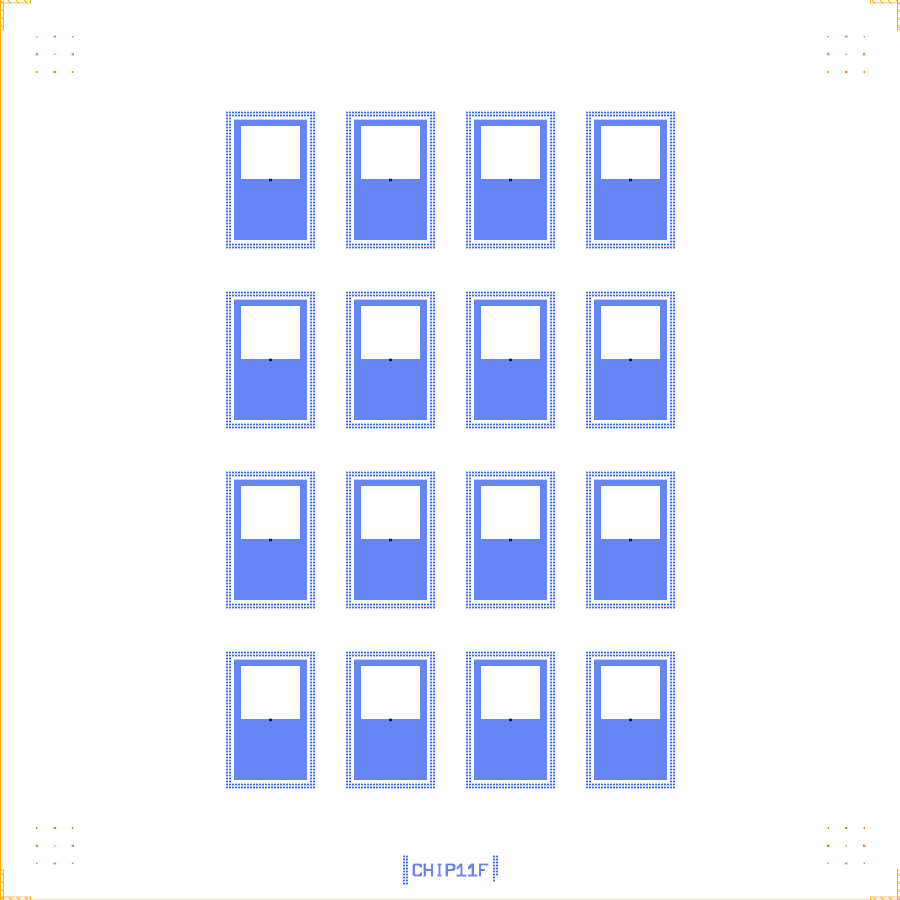

WindowsPath('build/legacy_steps/chip_11f_jjplacer_2_pairs.png')

In [6]:
with d.batch():
    for k, (x, y) in enumerate(SITES, 1):
        d.add(f"JX{k}", "ProbePadPair", **L.place(x, y, 0), junction_type="Trilayer Junction Compact",
              junction_params={"finger_width": FINGER, "second_finger_width": SECOND, "clearer": True},
              junction=L.jj(FINGER, SECOND), **PADS)       # pads ±5 µm from (x, y); the junction centred on it
print("pad edges at ±", GAP / 2, "µm from the site centre | JX window ±", WINDOW / 2)
L.step_snapshot(d, "2_pairs")

## 6 · Routes: does not apply

No routes: the test structures are probed directly (needles or wire bonds on their own pads), nothing is wired on
chip.

## 7 · Cheese, pads check and centring

**Cheese.** The source has no cheese, so the build draws the **PDK band** (`cheese: "auto"`): 3 rows of 5 µm squares
with 20 µm gaps around the 3/0 keep-outs, at least 4 µm from 3/0, never over empty ground (visible in the snapshots
as the dotted rings around each structure).

**Centring (PDK placement rule).** `L.center_circuit` measures the circuit (instances, free text labels left out) and
shifts the design so it sits in the middle of the die, each axis only if it is more than 50 µm off. Then the design
is saved, and `C.pads_md(d)` checks the pad rule (no bond pads).

centring shift (µm): (0.0, 0.0) | <Designer chip_11f_jjplacer: 16 instances, 0 routes, live=False> → examples\designs\legacy\chip_11f_jjplacer.json


| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| – | no bond pads or launchers | – | – | – |

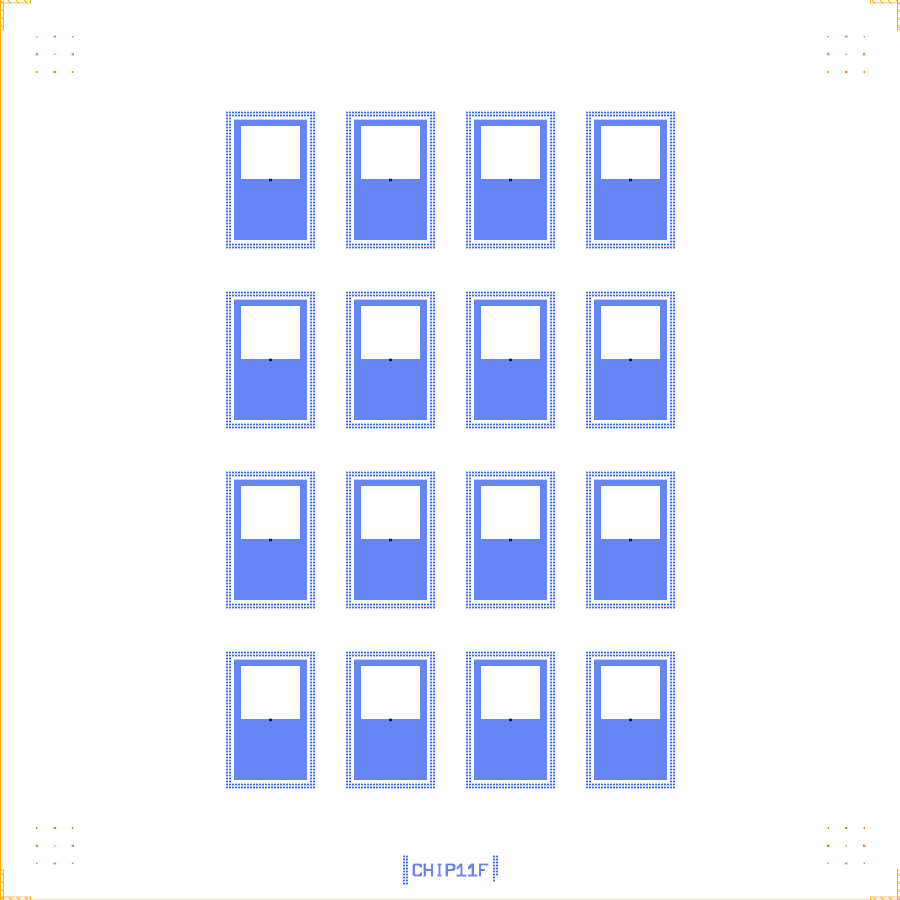

WindowsPath('build/legacy_steps/chip_11f_jjplacer_3_centred.png')

In [7]:
SHIFT = L.center_circuit(d)
DESIGN = d.save(OUT / f"{ID}.json")
print("centring shift (µm):", SHIFT, "|", d, "→", DESIGN)
display(Markdown(C.pads_md(d)))
L.step_snapshot(d, "3_centred")

## 8 · DRC

`d.drc()` builds the chip and checks it: **errors** (overlapping etch of unrelated cells, ports not landing,
parts outside the chip, a route looping over itself or running over a component) must be fixed; **warnings** are
reported for a person to judge (a dangling open end, two cells' bounding boxes touching); **PDK design warnings**
(`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`) flag values outside the PDK margins — they are never retuned for, only
listed. `C.pdk_report(d)` summarises the PDK checks: cheese source, content centring (free text labels left out),
junction types and the design warnings.

Expected (this run): **DRC clean (16 PDK design warnings)** — zero errors, no warnings (each `ProbePadPair` is one cell
holding the pads and the junction, with no ports); **16 `pdk_rn`**: every `JX_500` junction (0.2 × 0.6 µm) is 112.5
kΩ (L_J 16.84 nH), outside 40–50 kΩ — flagged, not retuned. `pdk_report`: cheese "PDK band", content centre
(+0, +0) µm, junction types `Trilayer Junction Compact` × 16. The device ID `CHIP11F` sits at the bottom edge centre.

In [8]:
drc = d.drc()
print(drc)
display(Markdown(C.pdk_report(d)))

DRC clean (16 PDK design warning(s))
design  pdk_rn        JX1: junction R_n 112.5 kΩ is outside the PDK window 40–50 kΩ (L_J 16.8361 nH)
design  pdk_rn        JX2: junction R_n 112.5 kΩ is outside the PDK window 40–50 kΩ (L_J 16.8361 nH)
design  pdk_rn        JX3: junction R_n 112.5 kΩ is outside the PDK window 40–50 kΩ (L_J 16.8361 nH)
design  pdk_rn        JX4: junction R_n 112.5 kΩ is outside the PDK window 40–50 kΩ (L_J 16.8361 nH)
design  pdk_rn        JX5: junction R_n 112.5 kΩ is outside the PDK window 40–50 kΩ (L_J 16.8361 nH)
design  pdk_rn        JX6: junction R_n 112.5 kΩ is outside the PDK window 40–50 kΩ (L_J 16.8361 nH)
design  pdk_rn        JX7: junction R_n 112.5 kΩ is outside the PDK window 40–50 kΩ (L_J 16.8361 nH)
design  pdk_rn        JX8: junction R_n 112.5 kΩ is outside the PDK window 40–50 kΩ (L_J 16.8361 nH)
design  pdk_rn        JX9: junction R_n 112.5 kΩ is outside the PDK window 40–50 kΩ (L_J 16.8361 nH)
design  pdk_rn        JX10: junction R_n 112.5 kΩ is o

| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, +0) µm |
| junction types | Trilayer Junction Compact × 16 |
| PDK design warnings | 16 (pdk_rn × 16) |
| pdk_rn | JX1: junction R_n 112.5 kΩ is outside the PDK window 40–50 kΩ (L_J 16.8361 nH) |
| pdk_rn | JX2: junction R_n 112.5 kΩ is outside the PDK window 40–50 kΩ (L_J 16.8361 nH) |
| pdk_rn | JX3: junction R_n 112.5 kΩ is outside the PDK window 40–50 kΩ (L_J 16.8361 nH) |
| pdk_rn | JX4: junction R_n 112.5 kΩ is outside the PDK window 40–50 kΩ (L_J 16.8361 nH) |
| pdk_rn | JX5: junction R_n 112.5 kΩ is outside the PDK window 40–50 kΩ (L_J 16.8361 nH) |
| pdk_rn | JX6: junction R_n 112.5 kΩ is outside the PDK window 40–50 kΩ (L_J 16.8361 nH) |
| pdk_rn | JX7: junction R_n 112.5 kΩ is outside the PDK window 40–50 kΩ (L_J 16.8361 nH) |
| pdk_rn | JX8: junction R_n 112.5 kΩ is outside the PDK window 40–50 kΩ (L_J 16.8361 nH) |
| pdk_rn | JX9: junction R_n 112.5 kΩ is outside the PDK window 40–50 kΩ (L_J 16.8361 nH) |
| pdk_rn | JX10: junction R_n 112.5 kΩ is outside the PDK window 40–50 kΩ (L_J 16.8361 nH) |
| pdk_rn | JX11: junction R_n 112.5 kΩ is outside the PDK window 40–50 kΩ (L_J 16.8361 nH) |
| pdk_rn | JX12: junction R_n 112.5 kΩ is outside the PDK window 40–50 kΩ (L_J 16.8361 nH) |

## 9 · Netlist and LOM

Each `ProbePadPair` carries one `JX_500` junction's lumped values (checked by `pdk_rn`), but the cell has no LOM model of
its own and the pads are not circuit elements, so the netlist is empty (only ground): a DC (R_n) test chip.

In [9]:
lb = d.lom()
C.show_netlist(lb)
print(C.lom_summary(lb))

**1 nodes · 0 branches · 0 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |

| branch | type | nodes | estimate |
|---|---|---|---|

**Unconnected ports:** none

{'nodes': 0, 'branches': 0, 'controls': 0, 'unconnected': 0}


## 10 · LOM simulation: does not apply — the junction table instead

Each `ProbePadPair` carries one `JX_500` junction (the pads are not circuit elements): a DC (R_n) test chip, no circuit
to simulate. The table gives the sixteen junctions on the PDK junction rule.

In [10]:
display(Markdown(L.junction_table([("JX_500 (`create_testPad(1.0, 0.6)`), ×16", FINGER, SECOND, 1)])))

PDK junction rule: Nb trilayer, Δ = 1.4 meV → I_c·R_n = πΔ/2e = 2.199 mV; PDK process R_n·A = 13500 Ω·µm² (J_c = 0.163 µA/µm²; nominal 0.5 × 0.6 µm → 45 kΩ, L_J 6.73 nH), C_J = 50 fF/µm² (R_n·A and C_J assumed by the PDK).

Drawn junctions (legacy fingers) on the PDK process:

| junction | fingers (µm) | n | area (µm²) | R_n (kΩ) | I_c (nA) | L_J (nH) | C_J (fF) |
|---|---|---|---|---|---|---|---|
| JX_500 (`create_testPad(1.0, 0.6)`), ×16 | 0.2 × 0.6 | 1 | 0.1200 | 112.50 | 19.5 | 16.836 | 6.00 |

**Reading the numbers** (this run): each JX_500 (0.2 × 0.6 µm = 0.12 µm²) is 112.5 kΩ, I_c 19.5 nA, L_J 16.84 nH, C_J
6 fF: 2.5 × the PDK nominal 45 kΩ.

## 11 · FEM: send the job — does not apply

A FEM job needs a sim group: a qubit / resonator cut-out with a port to excite. This chip has none (probe
structures only), so `C.export_sims(DESIGN)` exports nothing and `L.fem_send` says so. The cell stays so the
notebook has the same shape as the others (and `RUN_FEM` would have nothing to solve).

In [11]:
RUN_FEM = False                       # nothing to solve: the chip has no sim groups
jobs = C.export_sims(DESIGN)
display(Markdown(C.jobs_md(jobs) if jobs else "*no sim groups — nothing to export*"))
display(Markdown(L.fem_send(jobs, run=RUN_FEM)))

*no sim groups — nothing to export*

AEDT on this machine: `C:\Program Files\AnsysEM\v241\Win64\ansysedt.exe` (v241)

No FEM jobs: this chip has no sim groups (nothing to excite).

## 12 · Bring the results back — does not apply

No jobs, so no results to bring back (`L.fem_bring_back` says "No FEM jobs."). On a test chip the "results" are the
probe-station R_n values, compared with the junction table of step 10.

In [12]:
display(Markdown(L.fem_bring_back(d, DESIGN, jobs, groups=None)))

No FEM jobs.

## 13 · Iterate: change one property and rebuild

The JX_500's 112.5 kΩ is outside the PDK window on all sixteen sites (`pdk_rn` × 16). A copy gives the first pair's
junction a 0.5 µm straight finger (0.5 × 0.6 µm: the PDK nominal 45 kΩ), with the matching lumped values, rebuilds
it and runs the DRC again: one `pdk_rn` fewer. The copy is not saved; the chip keeps the legacy `JX_500`.

In [13]:
d2 = Designer.load(DESIGN, live=False, verbose=False)      # a copy of the saved design
jp = dict(d2.data["instances"]["JX1"]["params"]["junction_params"])
d2["JX1"].set(junction_params=jp | {"finger_width": 0.5}, junction=L.jj(0.5, SECOND))
display(Markdown(L.junction_table([("JX1 as drawn", FINGER, SECOND, 1), ("JX1, straight finger 0.5 µm", 0.5, SECOND, 1)])))
pdk_warnings = lambda rep: sum(i.rule.startswith("pdk_") for i in rep.issues)
print("PDK design warnings:", pdk_warnings(drc), "→", pdk_warnings(d2.drc()))

PDK junction rule: Nb trilayer, Δ = 1.4 meV → I_c·R_n = πΔ/2e = 2.199 mV; PDK process R_n·A = 13500 Ω·µm² (J_c = 0.163 µA/µm²; nominal 0.5 × 0.6 µm → 45 kΩ, L_J 6.73 nH), C_J = 50 fF/µm² (R_n·A and C_J assumed by the PDK).

Drawn junctions (legacy fingers) on the PDK process:

| junction | fingers (µm) | n | area (µm²) | R_n (kΩ) | I_c (nA) | L_J (nH) | C_J (fF) |
|---|---|---|---|---|---|---|---|
| JX1 as drawn | 0.2 × 0.6 | 1 | 0.1200 | 112.50 | 19.5 | 16.836 | 6.00 |
| JX1, straight finger 0.5 µm | 0.5 × 0.6 | 1 | 0.3000 | 45.00 | 48.9 | 6.734 | 15.00 |

PDK design warnings: 16 → 15


**Result** (this run): `JX1` with a 0.5 µm straight finger: R_n 112.5 → 45.0 kΩ (L_J 16.84 → 6.73 nH); the copy's DRC
has one `pdk_rn` fewer (16 → 15).

## 14 · Build and export

The design is saved as JSON (`DESIGN`, step 7): it is the source of truth — the layout, the netlist, the
FEM jobs and the mask are all made from it. The **fab mask** (`export_fab`) keeps only the PDK fab layers
(1/0 etch, 2/0 + 4/0 junction fingers, 3/0 second-metal keep-out, 50–53/0 spacer, 100/0 boundary, 1000/0 +
1001/0 markers), rounds the corners (radius ∝ each polygon's shortest dimension) and keeps the build's
cheese; every cheese hole of 1/0 is also on 3/0. **Simulation exports** never carry cheese; they drop airbridges
unless asked (`build_simulation(..., airbridges=True)`); the legacy chips have none.

Here: `cheese=True` (the default): the build already carries the PDK band (the source has no cheese), so the mask
keeps it (`cheese_source` "build"), on 1/0 and on 3/0.

The same from a shell:

```
qcc build examples/designs/legacy/chip_11f_jjplacer.json                    # layout → build/chip_11f_jjplacer.oas
qcc mask  examples/designs/legacy/chip_11f_jjplacer.json          # fab mask with the PDK rules
```

In [14]:
display(Markdown(L.fab_md(d)))

Fab mask: `build/chip_11f_jjplacer_fab.oas` · cheese source **build** (4644 PDK-band holes) · corner rounding on

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 4667 |
| 2/0 | JJ_STRAIGHT | 16 |
| 3/0 | M3 | 4663 |
| 4/0 | JJ_BENT | 16 |
| 50/0 | HSQ | 32 |
| 51/0 | SPACER_1 | 32 |
| 52/0 | SPACER_2 | 32 |
| 53/0 | SPACER_3 | 32 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

## 15 · Snapshots and comparison with the legacy geometry

Full die; one pad pair; its centre with the junction window over the two pad edges (1 µm overlap each).

Then the JX_500 cell drawn by the author's legacy script (run read-only through `tests/legacy_ref`:
`chip_11m_TestJJ16x_pads.create_testPad(1.0, 0.6)`), placed at the first site, moved by the centring shift, and the
XOR per junction layer against the rebuild (legacy 2/0, 4/0, HSQ 500/0 → PDK 50/0).

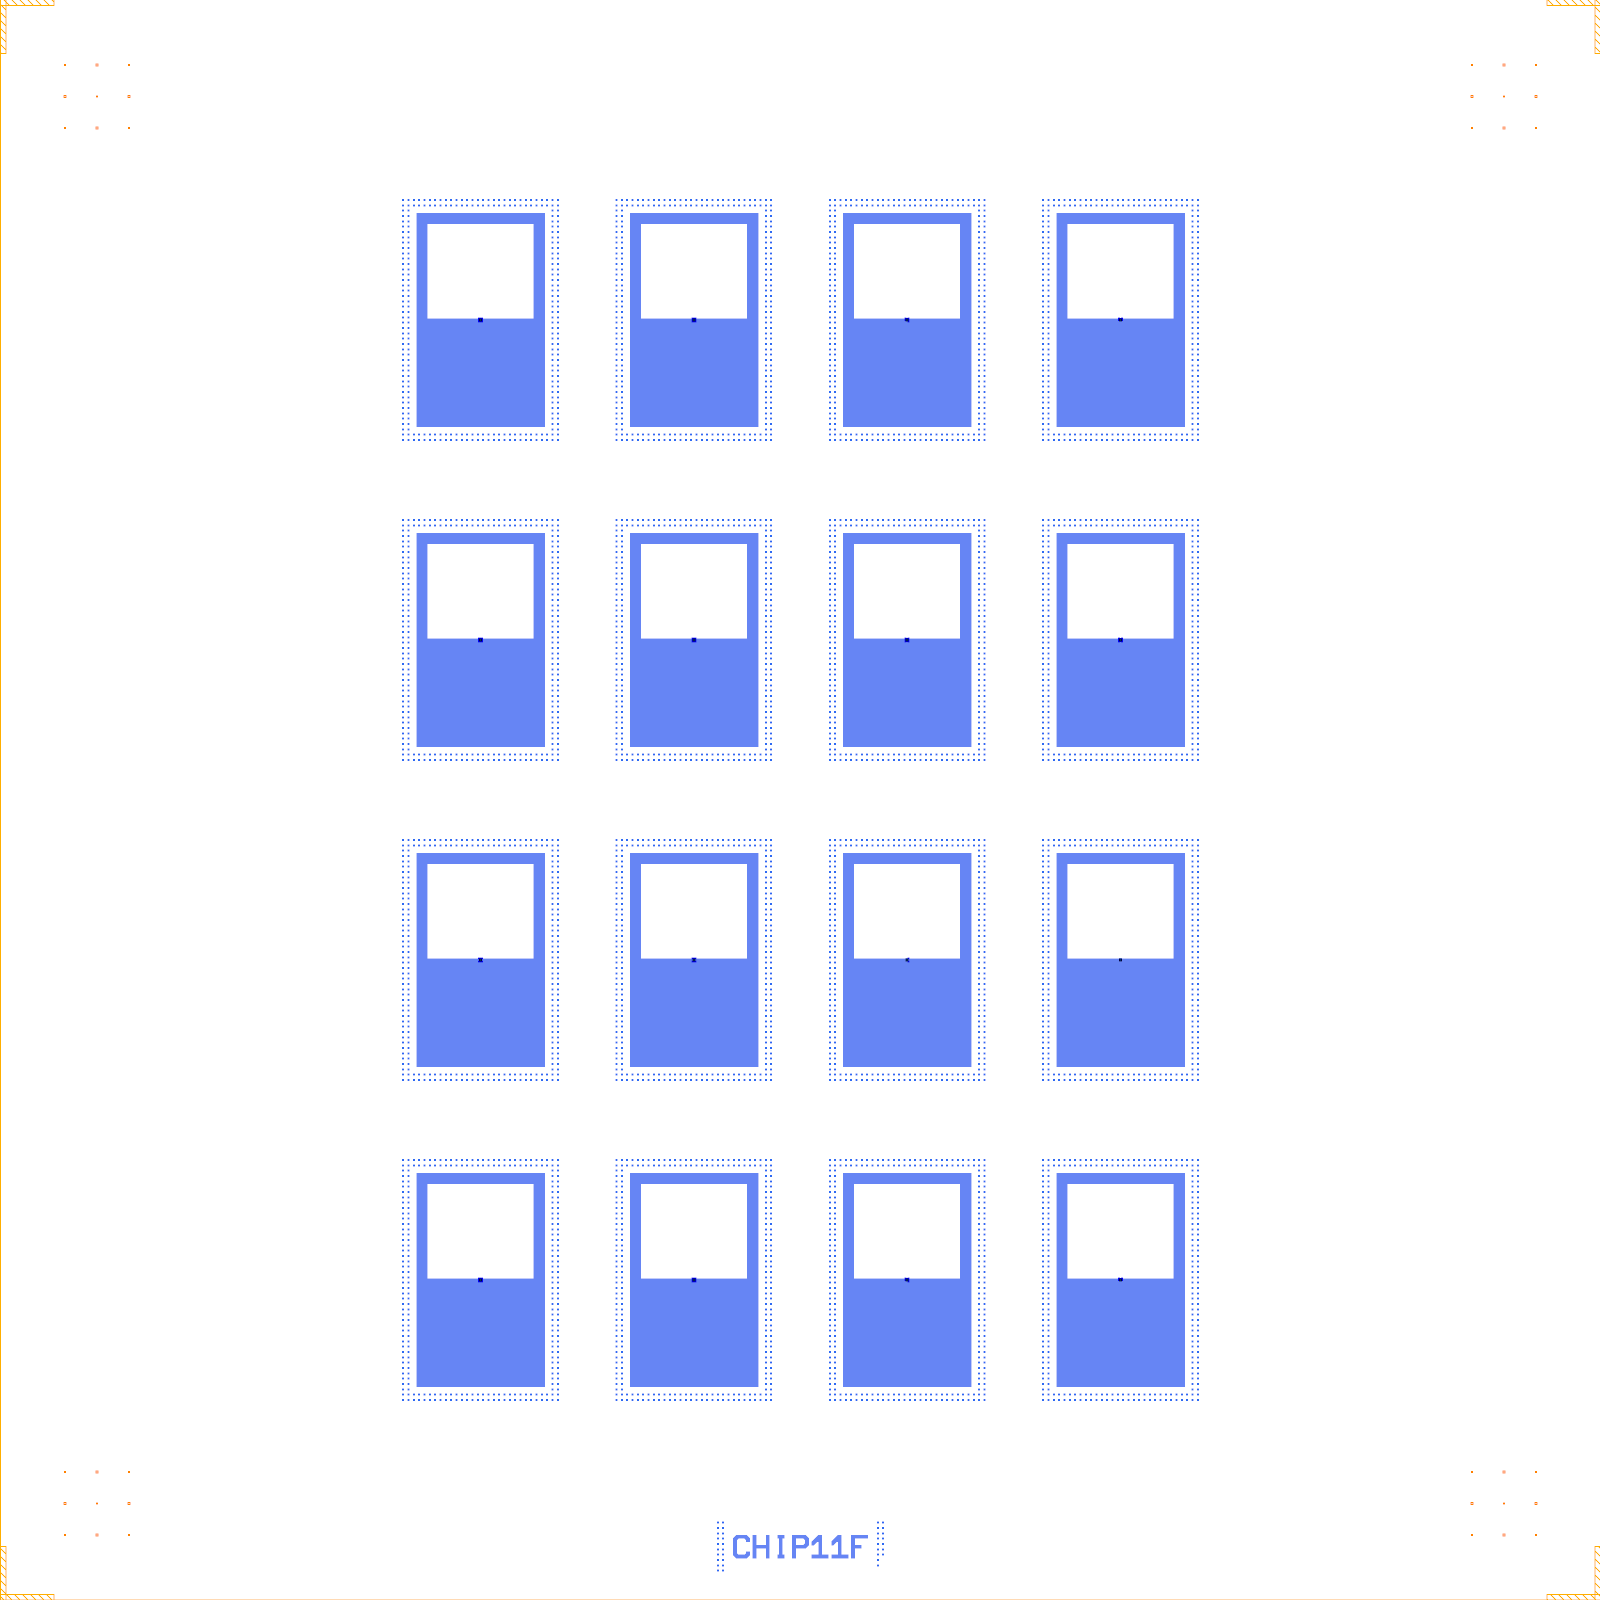

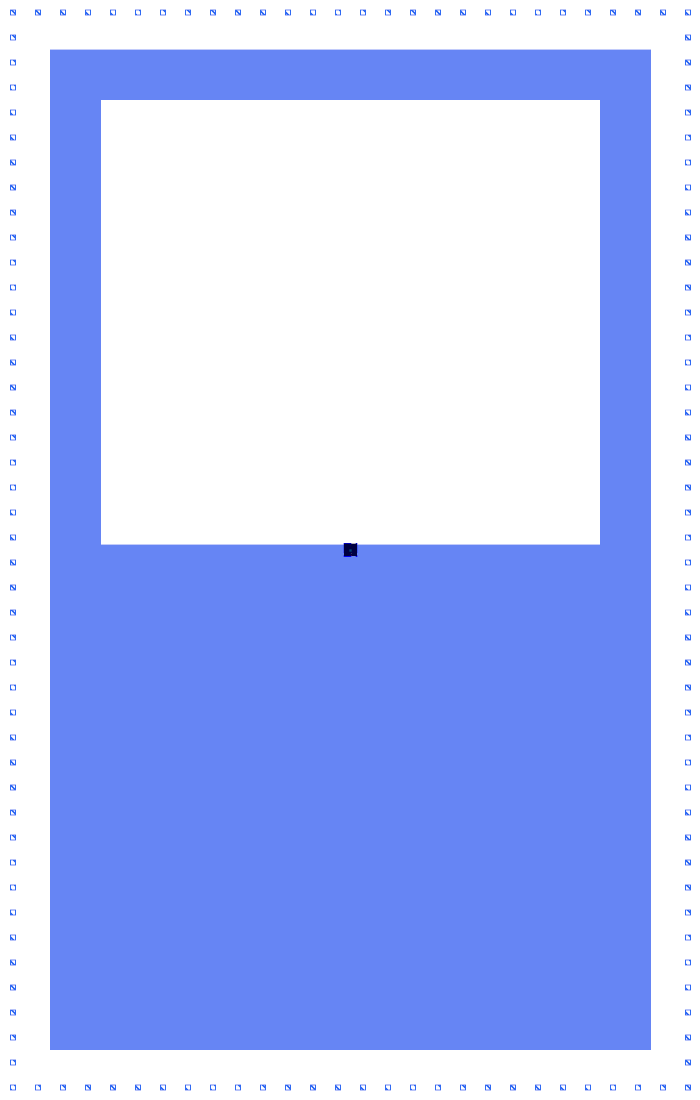

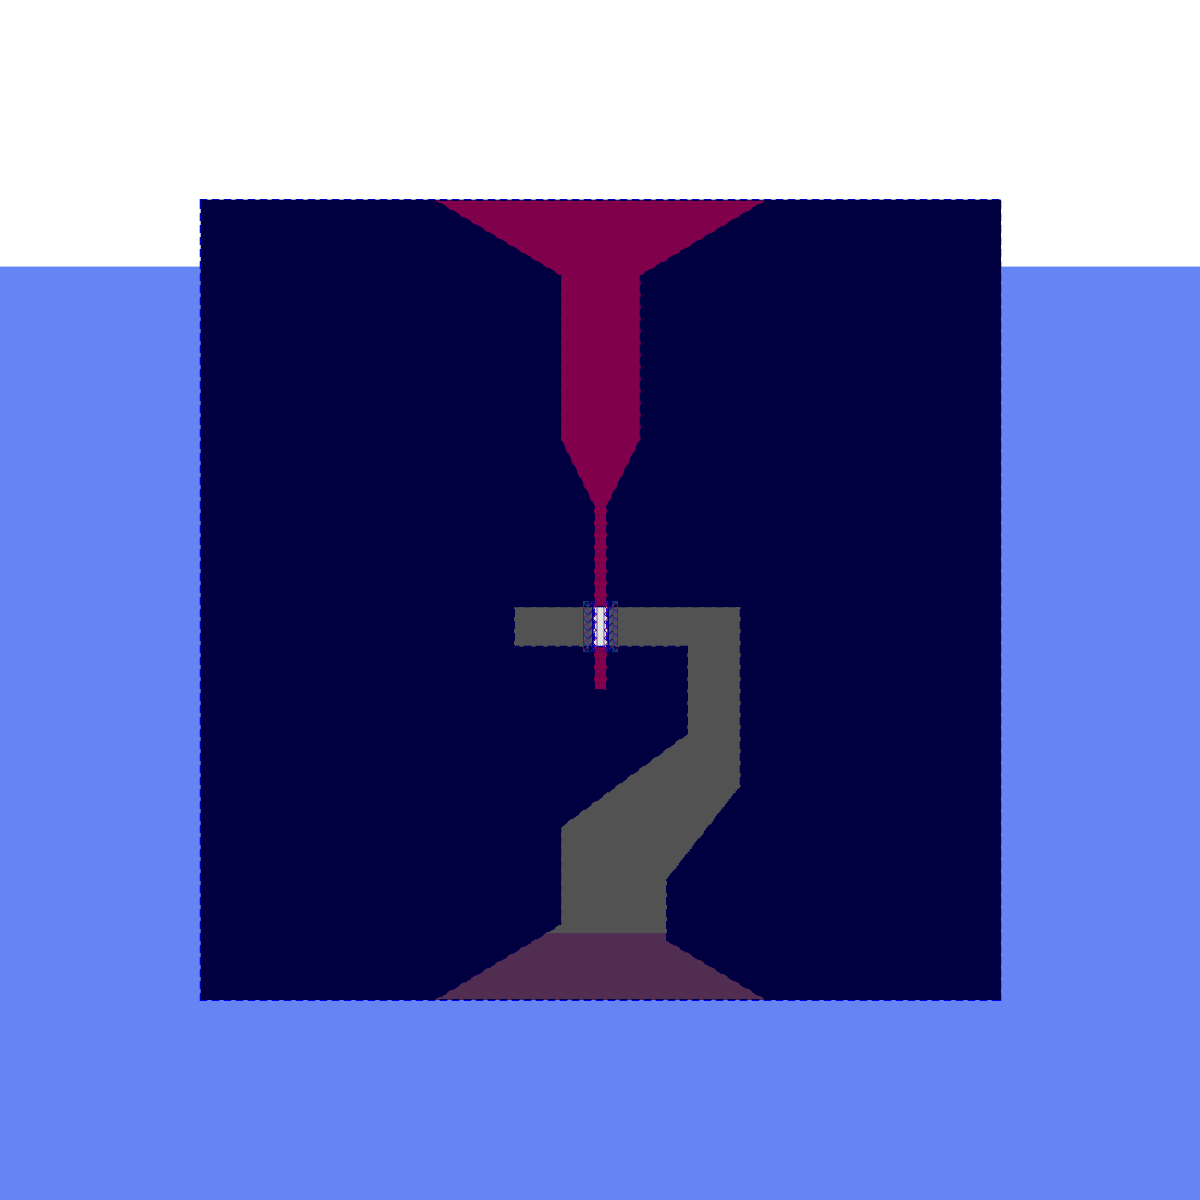

WindowsPath('examples/designs/legacy/chip_11f_jjplacer_jj.png')

In [15]:
(x0, y0) = L.origin(d, "JX1")
C.show_snapshot(d, OUT / f"{ID}.png", box=(0, 0, L.W, L.H))
C.show_snapshot(d, OUT / f"{ID}_pair.png", box=(x0 - 350, y0 - 550, x0 + 350, y0 + 550), size=(700, 1100), width=300)
C.show_snapshot(d, OUT / f"{ID}_jj.png", box=(x0 - 9, y0 - 9, x0 + 9, y0 + 9), size=(1200, 1200), width=360)

In [16]:
if L.legacy_available():
    ref = LB.legacy_chip(ID)
    cell = L.legacy_script_cell("chip_11m_TestJJ16x_pads.py", "create_testPad", "JX_500", SIZE, SECOND,
                                tmp="build/legacy_fix/chip_11f/jx")
    ref.cell_from("JX1", *cell, *SITES[0])
    ref = L.shift_reference(ref, *SHIFT)
    table, xor = LB.junction_xor(d, ref, names=["JX1"])
    print(f"largest junction-layer XOR {max(xor.values()):.4f} µm² ({max(xor, key=xor.get)})")
    display(Markdown(table))
else:
    print("components/ (legacy library) not present: no legacy reference")

largest junction-layer XOR 0.0000 µm² (('JX1', 'straight finger 2/0'))


| instance | layer | legacy (µm²) | rebuilt (µm²) | XOR (µm²) |
|---|---|---|---|---|
| JX1 | straight finger 2/0 | 136.264 | 136.264 | 0.0000 |
| JX1 | bent finger 4/0 | 132.442 | 132.442 | 0.0000 |
| JX1 | HSQ spacer (legacy 500/0 → 50/0) | 0.300 | 0.300 | 0.0000 |

## 16 · Summary

- **Matches the source:** the `JX_500` junction cell on every junction layer (XOR 0 µm² against the legacy
  `create_testPad(1.0, 0.6)` at the first site).
- **Rebuilt by decision (#23):** 16 `ProbePadPair`s, each junction centred in its pair's gap with a 1 µm window
  overlap onto each pad (site count, pitch and pad lead assumed: the CSV and the pad mask are lost).
- **Differs, by the PDK:** the PDK die frame and device ID `CHIP11F`, the PDK cheese band (fab cheese source
  "build", 4644 holes). Centring shift (0, 0).
- **Steps that do not apply:** pads, routes, LOM simulation (junction table instead), FEM.
- **Open:** 16 `pdk_rn` (112.5 kΩ); a 0.5 µm straight finger would give the PDK nominal (step 13).